La funzione è finita? True
La funzione è positiva? True
La funzione è simmetrica? True
La funzione in 0 torna B+I0? True


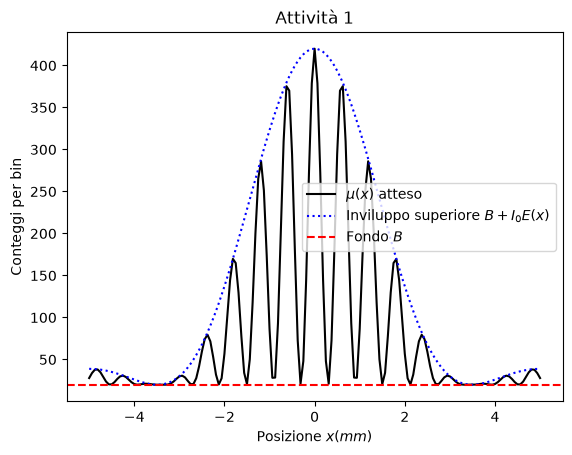

In [8]:
import numpy as np
import matplotlib.pyplot as plt

#ATTIVITA' 1

#INSERIMENTO DELLE COSTANTI
B = 20.0
I0 = 400.0
ALPHA = 0.9
DELTA = 5.2

#CREAZIONE ARRAY CON 161 VALORI EQUIDISTANTI TRA -5 E 5
x = np.linspace(-5,5,161)

#CREAZIONE F(X) E F(-X) DI E_X, C_X, MU_X

E_X = np.sinc(ALPHA*x/np.pi)**2
E__X = np.sinc(ALPHA*(-x)/np.pi)**2

C_X = (np.cos(DELTA*x))**2
C__X = (np.cos(DELTA*(-x)))**2

MU_X = B + I0 * C_X * E_X
MU__X = B + I0 * C__X * E__X

#VERIFICHE CONDIZIONI NECESSARIE

print("La funzione è finita?", (np.all(np.isfinite(MU_X)))) 
print("La funzione è positiva?",np.all(MU_X>=0))
print("La funzione è simmetrica?", np.all(MU_X == MU__X))
print("La funzione in 0 torna B+I0?", MU_X[80] == B + I0)

#CREAZIONE E STAMPA DEI GRAFICI DELLA FUNZIONE, IL FONDO E L'INVILUPPO

plt.title('Attività 1') #TITOLO
plt.plot(x, MU_X, label=r'$\mu(x)$ atteso', color='black') #CREIAMO FUNZIONE DI MU_X
plt.plot(x, B + I0 * E_X, color='blue', linestyle=':', label=r'Inviluppo superiore $B + I_0 E(x)$') #CREIAMO L'INVILUPPO SUPERIORE
plt.axhline(B, color='red', linestyle='--', label=r'Fondo $B$') #CREIAMO IL FONDO 
plt.xlabel('Posizione $x (mm)$') #DESCRIZIONE ASSE X
plt.ylabel('Conteggi per bin') #DESCRIZIONE ASSE Y
plt.legend() #CREAZIONE LEGENDA
plt.show() #STAMPIAMO IL GRAFICO A SCHERMO

La differenza è compatibile con la fluttuazione statistica? [ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  Tr

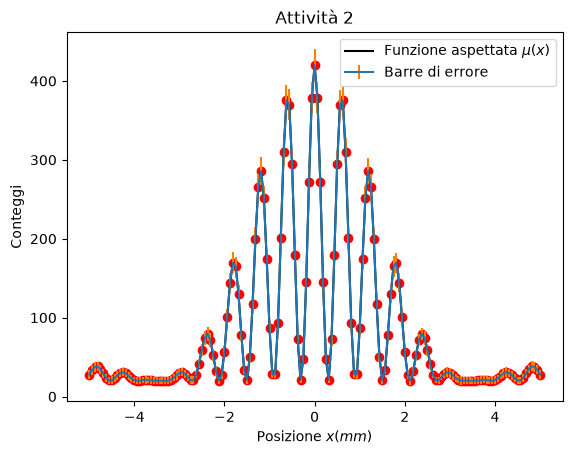

In [9]:
#CREIAMO DEI NUMERI CASUALI (CHIUDENDO IL SEED PER FACILITARE LA RIPRODUCIBILITA' DEGLI ESPERIMENTI)
rng = np.random.default_rng(42)

#APPLICHIAMO LA DISTIBUZIONE DI POISSON
N_I = rng.poisson(MU_X)
ERROR_X=np.sqrt(N_I)

#PRENDIAMO UN RANGE DI ERRORE MINIMO PARI AD 1
if (np.all(ERROR_X<1)):
    ERROR_X==1

#VOGLIAMO CHE LE X SFRUTTATE NELLE SOMMATORIE ABBIANO VALORE MINORE DI 1.2
FILTRO = np.abs(x)<1.2

#CALCOLIAMO LE SOMMATORIE
N_C=np.sum(N_I[FILTRO])
MU_C=np.sum(MU_X[FILTRO])

#VALUTIAMO CHE FLUTTUAZIONE E DIFFERENZA SIANO COMPATIBILI
print("La differenza è compatibile con la fluttuazione statistica?", (N_C-MU_C)/ERROR_X<1)

#OSSERIAMO IL TIPO DELLE SOMMATORIE E DELLA NOSTRA DISTRIBUZIONE DI POISSON (PIU' LA DIMENSIONE DI EVENTUALI VETTORI)  
print("\nTipo n_i ", type(N_I))
print("Size n_i ", len(N_I))
print("Tipo N_C ", type(N_C))
print("Tipo MU_C ", type(MU_C))

#GENERIAMO IL GRAFICO
plt.title('Attività 2') #TITOLO
plt.plot(x,MU_X, color="k", label=r'Funzione aspettata $\mu(x)$') #CURVA DI MU_X
plt.errorbar(x,MU_X,ERROR_X, ecolor="#FF8000", label=r'Barre di errore') #BARRE DI ERRORE
plt.scatter(x,MU_X,color="r") #RAPPRESENTAZIONE DI MU_X SOTTO FORMA DI PUNTI SU CUI VENGONO APPLICATE LE BARRE DI ERRORE (PROCESSO AUTOMATICO)
plt.xlabel('Posizione $x (mm)$') #DESCRIZIONE ASSE X
plt.ylabel('Conteggi') #DESCRIZIONE ASSE Y
plt.legend() #CREAZIONE LEGENDA
plt.show() #COMANDO PER STAMPARE IL GRAFICO A SCHERMO

Media simulata di Nc:  7648.479
Deviazione standard della distribuzione:  86.46856055805769
Errore sulla media:  1.9334957932437413
Scarto relativo:  -0.00012210634884214297


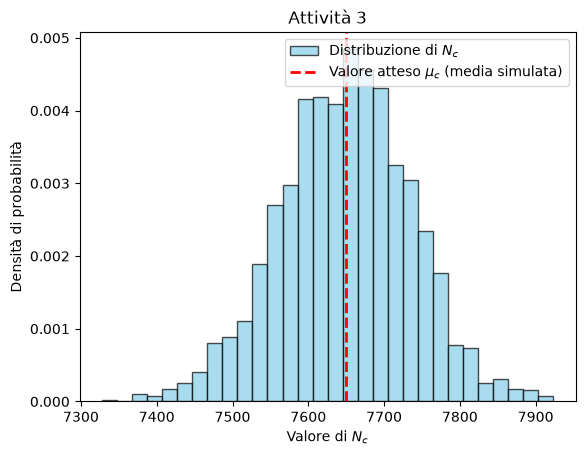

In [10]:
J=0

ARRAY_NC= np.zeros(2000) #CREIAMO UN ARRAY

#CREIAMO UN CICLO WHILE PER RIPETERE L'ESPERIMENTO 2000 VOLTE OGNI VOLTA CON RISULTATI DIFFERENTI

while(J<2000):
    rngc = np.random.default_rng(J)
    N_IC = rngc.poisson(MU_X)   
    N_CC=np.sum(N_IC[FILTRO])
    ARRAY_NC[J]=(N_CC) #OGNI RISULTATO VIENE INSERITO COME ELEMENTO DELL'ARREY DA 2000 ELEMENTI PRECEDENTEMENTE CREATO
    J=J+1

# CALCOLIAMO MEDIA, DEVIAZIONE STANDARD, ERRORE SULLA MEDIA E LO SCARTO MEDIO
media = (np.sum(ARRAY_NC)/2000)
Dev_st = np.std(ARRAY_NC, ddof=1)
err_media = Dev_st / np.sqrt(2000)
Scarto_media = (media - MU_C) / MU_C

#STAMPIAMO A SCHERMO QUANTO CALCOLATO PRECEDENTEMENTE

print('Media simulata di Nc: ', media)
print('Deviazione standard della distribuzione: ', Dev_st)
print('Errore sulla media: ', err_media)
print('Scarto relativo: ', Scarto_media )

#CREIAMO IL GRAFICO DELLE DISTRIBUZIONI DI PROBABILITà DEI RISULTATI 

plt.title('Attività 3') #TITOLO
plt.hist(ARRAY_NC, bins=30, density=True, edgecolor='black', alpha=0.7, color='skyblue', label='Distribuzione di $N_c$') #CREA IL GRAFICO AD ISTOGRAMMI DEL NOSTRO ARRAY 
plt.axvline(MU_C, color='red', linestyle='--', linewidth=2, label=r'Valore atteso $\mu_c$ (media simulata)') #INDIVIDUIAMO LA MEDIA
plt.xlabel(r'Valore di $N_c$') #DESCRIZIONE ASSE X
plt.ylabel('Densità di probabilità') #DESCRIZIONE ASSE Y
plt.legend() #CREAZIONE LEGENDA
plt.show() #STAMPIAMO IL GRAFICO